# Lista de Exercícios 4: Gradiente de Política

#### Disciplina: Aprendizado por Reforço
#### Professor: Luiz Chaimowicz
#### Monitores: Marcelo Lemos e Ronaldo Vieira

---

## Instruções

- ***SUBMISSÕES QUE NÃO SEGUIREM AS INSTRUÇÕES A SEGUIR NÃO SERÃO AVALIADAS.***
- Leia atentamente toda a lista de exercícios e familiarize-se com o código fornecido antes de começar a implementação.
- Os locais onde você deverá escrever suas soluções estão demarcados com comentários `# YOUR CODE HERE` ou `YOUR ANSWER HERE`.
- **Não altere o código fora das áreas indicadas, nem adicione ou remova células. O nome deste arquivo também não deve ser modificado.**
- Antes de submeter, certifique-se de que o código esteja funcionando do início ao fim sem erros.
- Submeta apenas este notebook (*ps4.ipynb*) com as suas soluções no Moodle.
- Prazo de entrega: 20/11/2025. Submissões fora do prazo terão uma penalização de -20% da nota final por dia de atraso.
- Utilize a [documentação do Gymnasium](https://gymnasium.farama.org/) para auxiliar sua implementação.
- Em caso de dúvidas entre em contato pelo fórum "Dúvidas com relação aos exercícios e trabalho de curso" no moodle da Disciplina.

---

## Cart Pole

Cart Pole é um ambiente no qual o agente precisa equilibrar um pêndulo invertido acoplado a um carrinho que se move horizontalmente. O objetivo é evitar que o pêndulo caia, controlando a posição do carrinho de maneira apropriada. O desafio está em manter o equilíbrio do sistema aplicando forças para a esquerda ou para a direita, de modo a contrabalançar a inclinação do pêndulo.

![Cart Pole](https://gymnasium.farama.org/_images/cart_pole.gif)

O espaço de observação é contínuo e composto por quatro variáveis: a posição e a velocidade do carrinho, o ângulo do pêndulo e a velocidade angular do pêndulo. O agente pode escolher entre duas ações discretas: aplicar uma força no carrinho para a esquerda ou para a direita. O estado inicial de cada episódio é definido de forma aleatória, com todos os valores dentro do intervalo $(−0.05, 0.05)$. O sempre sistema começa em uma configuração próxima do equilíbrio vertical, mas com pequenas variações.

O episódio termina quando o ângulo do pêndulo em relação ao eixo vertical excede 12 graus, quando o carrinho se afasta mais de 2.4 unidades de distância do centro, ou quando o limite de 500 passos é atingido. A cada passo, o agente recebe uma recompensa de $1$, incentivando-o a manter o sistema estável pelo maior tempo possível. Para mais detalhes sobre o ambiente leia a [documentação do gymnasium](https://gymnasium.farama.org/environments/classic_control/cart_pole/).

Nesta lista de exercícios, você irá trabalhar com o ambiente Cart Pole descrito acima. Seu objetivo será implementar o algoritmo REINFORCE para solucionar este problema.

## REINFORCE

Nesta atividade, você implementará um agente baseado no algoritmo REINFORCE, utilizando uma **política linear com softmax**. Você será responsável por definir e inicializar os pesos da política, calcular o gradiente da função objetivo e realizar a atualização dos parâmetros ao longo do treinamento.

Siga as instruções abaixo para implementar seu agente:

1. Implemente o método `__init__` que inicializa um novo agente. Ele deve receber como parâmetros o espaço de observações, o espaço de ações, a taxa de aprendizado $\alpha$, e o fator de desconto $\gamma$. Inicialize os pesos do modelo na variável `self.weights`.
2. Implemente o método `softmax`, que recebe um vetor de preferências (logits) $z = (z_1,\dotsc,z_K) \in \mathbb{R}^K$ e retorna as probabilidades de cada ação segundo a função softmax $\sigma(z)_i = \frac{e^{z_i}}{\sum_{j=1}^{K} e^{z_j}}$, para $i = 1, \dotsc, K.$
3. Implemente o método `choose_action`, responsável por escolher uma ação a partir de um estado observado.
4. Implemente o método `learn`, que atualiza os pesos do agente com base na experiência obtida durante a interação com o ambiente.
5. Implemente o método `train`, que executa o loop de treinamento do algoritmo REINFORCE. O ambiente de treinamento e o número de episódios devem ser fornecidos como parâmetros de entrada. O método deve retornar uma lista com a soma das recompensas obtidas ao longo de cada episódio.

In [17]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
class ReinforceAgent:
    def __init__(self, observation_space, action_space, alpha, gamma):
        self.observation_space = observation_space.shape[0]
        self.action_space = action_space.n
        self.alpha = alpha
        self.gamma = gamma
        self.weights = np.random.randn(self.action_space, self.observation_space) * 0.01

    def softmax(self, z):
        e_z = np.exp(z - np.max(z))
        return e_z / np.sum(e_z)

    def choose_action(self, state):
        logits = self.weights @ state
        probabilities = self.softmax(logits)
        action = np.random.choice(self.action_space, p=probabilities)
        return action

    def learn(self, trajectories):
        states, actions, rewards = zip(*trajectories)

        returns = []
        G = 0
        for r in reversed(rewards):
            G = r + self.gamma * G
            returns.insert(0, G)

        for state, action, Gt in zip(states, actions, returns):

            logits = self.weights @ state
            probabilities = self.softmax(logits)

            one_hot = np.zeros(self.action_space)
            one_hot[action] = 1

            grad_log_pi = (one_hot - probabilities)[:, None] @ state[None, :]

            self.weights += self.alpha * Gt * grad_log_pi

    def train(self, env, episodes):
        episode_returns = []

        for ep in range(episodes):
            state, _ = env.reset()
            done = False
            trajectory = []
            total_reward = 0

            while not done:
                action = self.choose_action(state)
                next_state, reward, terminated, truncated, _ = env.step(action)
                done = terminated or truncated

                trajectory.append((state, action, reward))
                total_reward += reward

                state = next_state

            self.learn(trajectory)
            episode_returns.append(total_reward)

            if ep % 100 == 0:
                print(f"Episode {ep}, Return = {total_reward}")

        return episode_returns

In [19]:
# Não altere ou remova esta célula

6. Treine um novo agente no ambiente Cart Pole por 2000 episódios. Escolha parâmetros $\alpha$ e $\gamma$ de acordo com o desempenho do seu modelo. Armazene os retornos episódicos, obtidos no método `train`, na variável `reinforce_returns`.

In [20]:
env = gym.make("CartPole-v1")

alpha = 0.001
gamma = 0.99
episodes = 2000

agent = ReinforceAgent(
    observation_space=env.observation_space,
    action_space=env.action_space,
    alpha=alpha,
    gamma=gamma
)

reinforce_returns = agent.train(env, episodes)

env.close()

Episode 0, Return = 16.0
Episode 100, Return = 94.0
Episode 200, Return = 216.0
Episode 300, Return = 204.0
Episode 400, Return = 129.0
Episode 500, Return = 201.0
Episode 600, Return = 222.0
Episode 700, Return = 337.0
Episode 800, Return = 389.0
Episode 900, Return = 500.0
Episode 1000, Return = 500.0
Episode 1100, Return = 500.0
Episode 1200, Return = 500.0
Episode 1300, Return = 500.0
Episode 1400, Return = 500.0
Episode 1500, Return = 500.0
Episode 1600, Return = 500.0
Episode 1700, Return = 500.0
Episode 1800, Return = 500.0
Episode 1900, Return = 500.0


In [21]:
# Não altere ou remova esta célula

## Análise

7. Utilize a biblioteca matplotlib para gerar um gráfico dos retornos episódicos obtidos pelo agente, armazenados na variável `reinforce_returns` no exercício anterior. Caso os dados apresentem muita variação, aplique uma média móvel para suavizar a curva e evidenciar melhor a tendência de aprendizado. Adicione um título e rótulos de eixos apropriados para facilitar a interpretação.

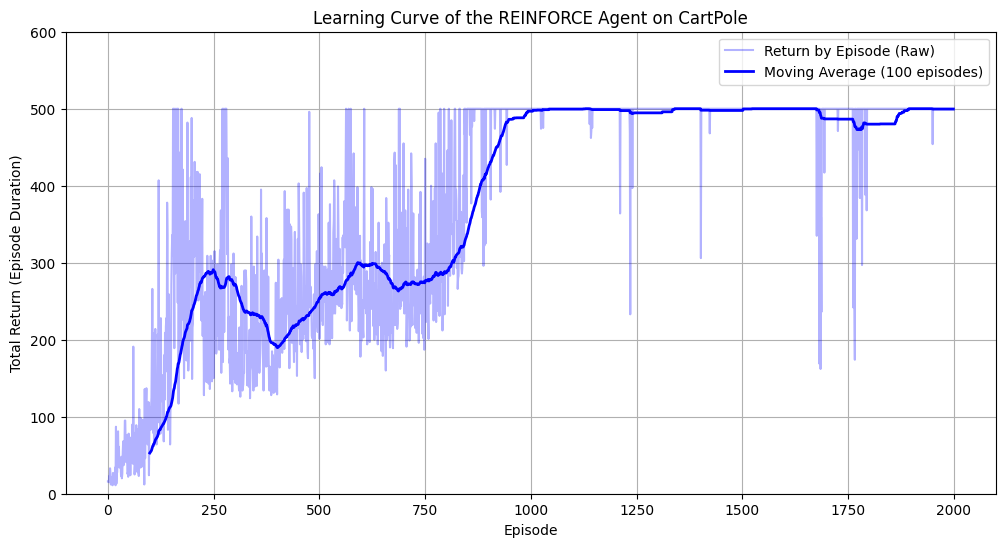

In [22]:
def moving_average(data, window_size):
    return np.convolve(data, np.ones(window_size)/window_size, mode='valid')

window_size = 100
smoothed_returns = moving_average(reinforce_returns, window_size)
smoothed_x = np.arange(window_size - 1, len(reinforce_returns))

plt.figure(figsize=(12, 6))
plt.plot(reinforce_returns, label='Return by Episode (Raw)', color='blue', alpha=0.3)
plt.plot(smoothed_x, smoothed_returns, label=f'Moving Average ({window_size} episodes)', color='blue', linewidth=2)

plt.title('Learning Curve of the REINFORCE Agent on CartPole')
plt.xlabel('Episode')
plt.ylabel('Total Return (Episode Duration)')

plt.ylim(0, 600)
plt.legend()
plt.grid(True)

plt.show()

8. Durante o treinamento, o seu agente apresentou instabilidades, como variações bruscas na recompensa ou dificuldade em convergir? Que estratégias poderiam ser adotadas para mitigar instabilidades neste algoritmo?

O algoritmo reinforce geralmente apresenta instabilidades durante o treinamento, como oscilações bruscas na recompensa ou dificuldade temporária de convergência, porque depende de retornos Monte Carlo, que possuem alta variância e tornam os gradientes ruidosos. No gráfico gerado, podemos observar as oscilações nos dados brutos (azul claro) durante todos os episódios. Nos dados suavizados (azul), próximo ao episódio 900, observamos que os resultados convergiram, alcançando o limite estipulado de 500 passos, que era resultado o desejado. 

Para mitigar esses problemas, podemos adotar técnicas como a inclusão de um baseline (que reduz a variância sem introduzir viés), diminuição da taxa de aprendizado, normalização dos retornos dentro de cada episódio, aplicação de gradient clipping e inicialização de pesos em escala reduzida. Além disso, métodos mais avançados como Actor-Critic também podem ser usados para estabilizar o aprendizado combinando Monte Carlo e bootstrapping.

9. Explique qual é o papel da função softmax na definição da política. Por que, nesse contexto, não é suficiente escolher apenas a ação com maior valor?

A função softmax transforma as preferências lineares do agente em probabilidades, garantindo que a política seja estocástica e diferenciável, características essenciais para o cálculo do gradiente no algoritmo reinforce. Em vez de sempre escolher a ação de maior valor, a política softmax atribui probabilidades proporcionais a qualidade das ações, mantendo um nível necessário de exploração e evitando que a política se torne determinística cedo demais, o que impediria o agente de descobrir estratégias melhores e comprometeria o processo de otimização baseado em gradientes.

10. Por que o algoritmo REINFORCE precisa aguardar a conclusão de todo o episódio antes de realizar atualizações nos parâmetros da política?

O reinforce precisa aguardar a conclusão do episódio completo porque suas atualizações dependem do retorno total, calculado a partir de toda a sequência de recompensas acumuladas desde cada passo até o final. Como esse retorno só é conhecido quando o episódio acaba, o algoritmo é obrigado a trabalhar de forma Monte Carlo, atualizando os parâmetros apenas após observar a trajetória inteira. Isso elimina viés na estimativa do gradiente, mas aumenta a variância e faz com que o aprendizado seja menos estável e mais sensível a flutuações nas trajetórias.